<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-2-reading-anova-output.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reading ANOVA Output

In this notebook we read the ANOVA table produced by software, check the assumptions behind it, and find out which groups differ.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Example: evaluating battery suppliers

You work as an analyst for a consumer electronics company that sources batteries from three suppliers. Before signing a long-term contract, your team tests seven batteries from each supplier and records how many hours each battery lasts.

In [ ]:
battery_data = pd.DataFrame({
    "Supplier A": [10.25, 9.93, 10.32, 9.76, 8.96, 9.08, 10.52],
    "Supplier B": [8.88, 8.27, 9.57, 8.27, 10.27, 8.68, 8.89],
    "Supplier C": [9.34, 9.92, 9.69, 10.36, 9.75, 10.65, 10.28],
})
batteries = battery_data.melt(var_name="supplier", value_name="hours")
batteries.groupby("supplier")["hours"].agg(["count", "mean", "std"])

,count,mean,std
supplier,,,
Supplier A,7,9.8314,0.6092
Supplier B,7,8.9757,0.7221
Supplier C,7,9.9986,0.4530


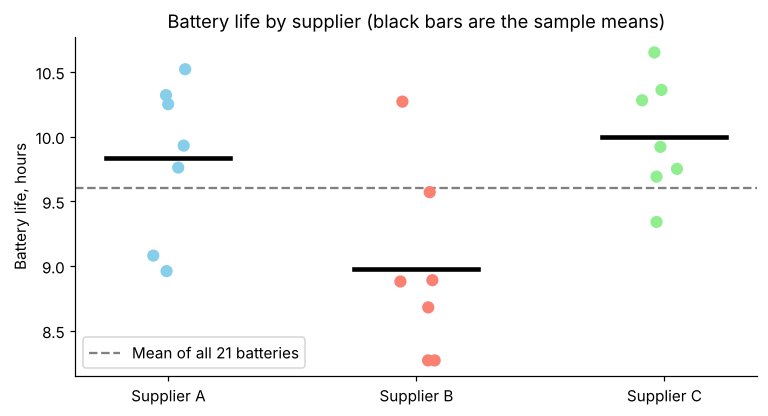

In [ ]:
palette = {"Supplier A": "skyblue", "Supplier B": "salmon", "Supplier C": "lightgreen"}
plt.figure(figsize=(8, 4))
sns.stripplot(data=batteries, x="supplier", y="hours", hue="supplier", palette=palette, legend=False, size=8, jitter=0.1)
for i, s in enumerate(battery_data.columns):
    plt.plot([i - 0.25, i + 0.25], [battery_data[s].mean()] * 2, color="black", lw=3)
plt.axhline(batteries["hours"].mean(), color="gray", ls="--", label="Mean of all 21 batteries")
plt.ylabel("Battery life, hours"); plt.xlabel(""); plt.title("Battery life by supplier (black bars are the sample means)")
plt.legend(); plt.show()

**Question to you:** what is the factor, what are the treatments, what are the experimental units, and what is the response variable?

## 2. Hypotheses

H<sub>0</sub>: μ<sub>A</sub> = μ<sub>B</sub> = μ<sub>C</sub>

H<sub>a</sub>: not all three population means are equal

The alternative says that **at least two** means differ. It does not say that all three are different.

## 3. The ANOVA table

In [ ]:
model = ols("hours ~ C(supplier)", data=batteries).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
anova_table["mean_sq"] = anova_table["sum_sq"] / anova_table["df"]
anova_table

,sum_sq,df,F,PR(>F),mean_sq
C(supplier),4.2150,2.0000,5.7596,0.0117,2.1075
Residual,6.5863,18.0000,NaN,NaN,0.3659


How to read the table:

- Row `C(supplier)`: variation **between** the suppliers' sample means. Its mean square is **MSTr**, the mean square due to treatments, with k − 1 = 2 degrees of freedom.
- Row `Residual`: variation **within** each supplier, battery to battery. Its mean square is **MSE**, the mean square due to error, with n<sub>T</sub> − k = 18 degrees of freedom.
- Each mean square is a sum of squares divided by its degrees of freedom.
- **F = MSTr / MSE.** If all population means are equal, MSTr and MSE estimate the same variance and F is close to 1.

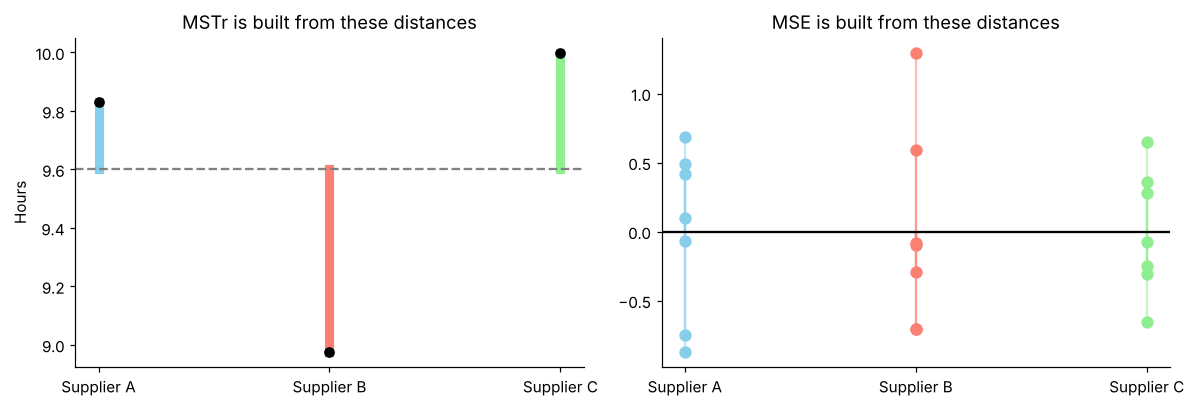

In [ ]:
grand = batteries["hours"].mean(); gm = batteries.groupby("supplier")["hours"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, s in enumerate(gm.index):
    axes[0].plot([i, i], [grand, gm[s]], color=palette[s], lw=6); axes[0].scatter(i, gm[s], color="black", zorder=3)
axes[0].axhline(grand, color="gray", ls="--"); axes[0].set_xticks(range(3)); axes[0].set_xticklabels(gm.index)
axes[0].set_title("MSTr is built from these distances"); axes[0].set_ylabel("Hours")
for i, s in enumerate(gm.index):
    v = battery_data[s]; axes[1].scatter(np.full(7, i), v - v.mean(), color=palette[s], s=50)
    for d in v - v.mean(): axes[1].plot([i, i], [0, d], color=palette[s], alpha=0.5)
axes[1].axhline(0, color="black"); axes[1].set_xticks(range(3)); axes[1].set_xticklabels(gm.index)
axes[1].set_title("MSE is built from these distances")
plt.tight_layout(); plt.show()

In [ ]:
mstr = anova_table.loc["C(supplier)", "mean_sq"]
mse = anova_table.loc["Residual", "mean_sq"]
f_stat = mstr / mse
p_value = anova_table.loc["C(supplier)", "PR(>F)"]
print(f"MSTr = {mstr:.3f}")
print(f"MSE  = {mse:.3f}  ->  a typical battery is about {np.sqrt(mse):.2f} hours from its supplier's mean")
print(f"F = MSTr / MSE = {f_stat:.3f}, p-value = {p_value:.4f}")

MSTr = 2.107
MSE  = 0.366  ->  a typical battery is about 0.60 hours from its supplier's mean
F = MSTr / MSE = 5.760, p-value = 0.0117


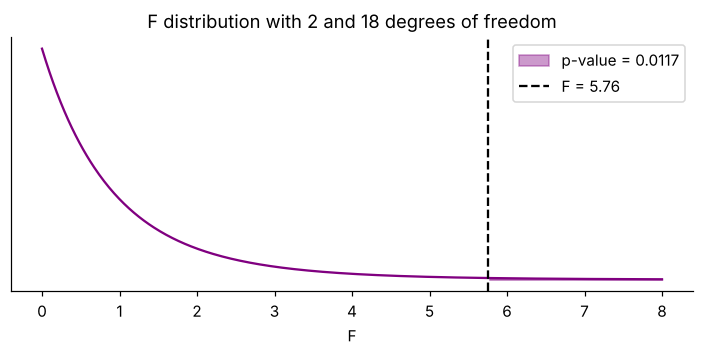

In [ ]:
x = np.linspace(0, 8, 500); y = stats.f.pdf(x, 2, 18)
plt.figure(figsize=(8, 3))
plt.plot(x, y, color="purple"); plt.fill_between(x, y, where=x >= f_stat, color="purple", alpha=0.4, label=f"p-value = {p_value:.4f}")
plt.axvline(f_stat, color="black", ls="--", label=f"F = {f_stat:.2f}")
plt.title("F distribution with 2 and 18 degrees of freedom"); plt.xlabel("F"); plt.yticks([]); plt.legend(); plt.show()

**Question to you:** what do you conclude at α = 0.05? Write the conclusion in the language of the problem.

## 4. Assumptions, independence first

1. **Independence.** The observations are independent, within and between groups. We judge this by how the data were collected, not by the numbers. If the seven batteries from a supplier came from one production batch, or were tested together on one charger, their lifetimes could be related, and the p-value would overstate the evidence. A larger sample does not fix this.
2. **Normality.** The response is approximately normal within each group.
3. **Equal variances.** The population variances are similar across groups.

With seven batteries per supplier, plots tell us only a little, but they can reveal serious problems.

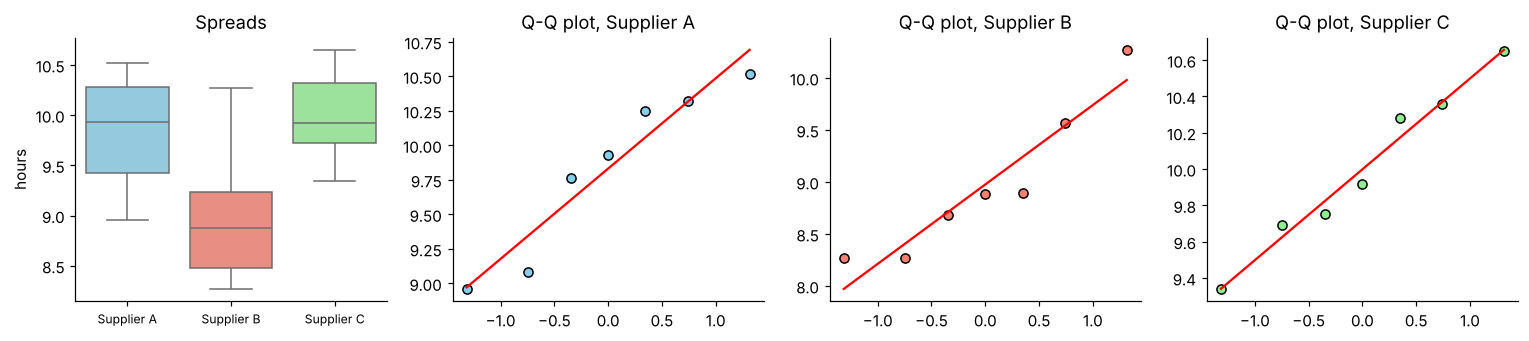

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
sns.boxplot(data=batteries, x="supplier", y="hours", hue="supplier", palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Spreads"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", labelsize=8)
for ax, s in zip(axes[1:], battery_data.columns):
    stats.probplot(battery_data[s], dist="norm", plot=ax)
    ax.get_lines()[0].set_color(palette[s]); ax.get_lines()[0].set_markeredgecolor("black")
    ax.set_title(f"Q-Q plot, {s}"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

No serious problems: the spreads are similar, and the points in the Q-Q plots stay close to the lines.

## 5. Which suppliers differ?

ANOVA tells us that at least two population means differ, but not which ones. Post hoc procedures compare the groups pair by pair, after a significant F test.

### Fisher's LSD

Fisher's Least Significant Difference is the two-sample t-test from Module 9 with one change: it uses MSE from the ANOVA table as the variance estimate, so it has n<sub>T</sub> − k degrees of freedom. Two means differ when the absolute difference between them exceeds

$$
LSD = t_{\alpha/2}\sqrt{MSE\left(\frac{1}{n_i} + \frac{1}{n_j}\right)}
$$

In [ ]:
from itertools import combinations

n_T, k = len(batteries), batteries["supplier"].nunique()
t_crit = stats.t.ppf(1 - 0.05 / 2, n_T - k)
lsd = t_crit * np.sqrt(mse * (1 / 7 + 1 / 7))
print(f"t = {t_crit:.3f}, LSD = {lsd:.3f} hours\n")

means = batteries.groupby("supplier")["hours"].mean()
for a, b in combinations(means.index, 2):
    diff = means[a] - means[b]
    print(f"{a} vs {b}: difference = {diff:6.3f}  ->  {'differ' if abs(diff) > lsd else 'not enough evidence'}")

t = 2.101, LSD = 0.679 hours

Supplier A vs Supplier B: difference =  0.856  ->  differ
Supplier A vs Supplier C: difference = -0.167  ->  not enough evidence
Supplier B vs Supplier C: difference = -1.023  ->  differ


Fisher's LSD runs every comparison at α = 0.05 and makes no adjustment for the number of comparisons, so the chance of at least one false "significant" pair is larger than 5%. The simplest adjustment is the **Bonferroni** idea: with m comparisons, test each one at α/m, here 0.05/3 ≈ 0.0167.

### Tukey's HSD

Tukey's Honestly Significant Difference adjusts for the number of comparisons directly. It keeps the chance of at least one false "significant" pair at α, so it is more conservative than Fisher's LSD.

In [ ]:
tukey = pairwise_tukeyhsd(batteries["hours"], batteries["supplier"])
print(tukey.summary())
q_crit = stats.studentized_range.ppf(0.95, k, n_T - k)
hsd = q_crit * np.sqrt(mse / 7)
print(f"\nFisher's LSD threshold: {lsd:.3f} hours")
print(f"Tukey's HSD threshold:  {hsd:.3f} hours")

    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
Supplier A Supplier B  -0.8557 0.0414 -1.6809 -0.0305   True
Supplier A Supplier C   0.1671 0.8641 -0.6581  0.9923  False
Supplier B Supplier C   1.0229 0.0142  0.1977  1.8481   True
------------------------------------------------------------

Fisher's LSD threshold: 0.679 hours
Tukey's HSD threshold:  0.825 hours


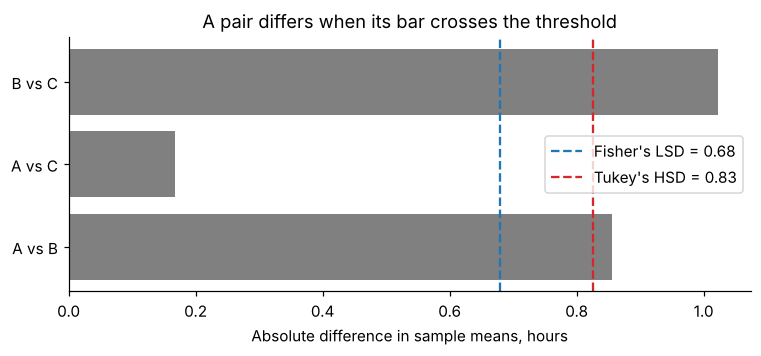

In [ ]:
pairs = [f"{a[-1]} vs {b[-1]}" for a, b in combinations(means.index, 2)]
diffs = [abs(means[a] - means[b]) for a, b in combinations(means.index, 2)]
plt.figure(figsize=(8, 3))
plt.barh(pairs, diffs, color="gray")
plt.axvline(lsd, color="tab:blue", ls="--", label=f"Fisher's LSD = {lsd:.2f}")
plt.axvline(hsd, color="tab:red", ls="--", label=f"Tukey's HSD = {hsd:.2f}")
plt.xlabel("Absolute difference in sample means, hours"); plt.title("A pair differs when its bar crosses the threshold")
plt.legend(loc="center right"); plt.show()

Both procedures find that Supplier B differs from A and from C, and that A and C cannot be told apart. Tukey's threshold is wider: a difference between 0.68 and 0.83 hours would count as significant under LSD but not under Tukey.

**Question to you:** the manager prefers Supplier C, which costs less than A, as long as its batteries last at least as long. What would you tell her?

## 6. Optional: where the numbers in the table come from

You will not need to compute these by hand, but the table contains nothing mysterious.

In [ ]:
sstr = (7 * (means - grand) ** 2).sum()
sse = ((batteries["hours"] - batteries.groupby("supplier")["hours"].transform("mean")) ** 2).sum()
print(f"SSTr = sum of 7 x (group mean - overall mean)^2 = {sstr:.4f}")
print(f"SSE  = sum of (observation - its group mean)^2  = {sse:.4f}")
print(f"MSTr = SSTr / (k - 1) = {sstr / (k - 1):.4f}")
print(f"MSE  = SSE / (n_T - k) = {sse / (n_T - k):.4f}")

SSTr = sum of 7 x (group mean - overall mean)^2 = 4.2150
SSE  = sum of (observation - its group mean)^2  = 6.5863
MSTr = SSTr / (k - 1) = 2.1075
MSE  = SSE / (n_T - k) = 0.3659
